# Projeto Integrador Avançado: VulcanTech Smart Metals S.A.
## Etapa 1: Diagnóstico Estrutural, Saneamento Físico, Normalização por Lote e Feature Engineering Industrial

Este notebook executa o diagnóstico completo dos dados de telemetria das células industriais de manufatura flexível (`CEL-201` a `CEL-204`), aplica saneamento de ruídos físicos e sensores defeituosos, executa interpolação temporal e deriva variáveis físicas como o **Índice de Esforço Mecânico (IEM)**, normalização por liga metálica e estatísticas móveis dinâmicas (30 min e 2 horas).

In [1]:
import os
from pathlib import Path
import sys

# Define e adiciona a raiz do projeto ao path do Python
caminho_raiz = Path.cwd().parent
if str(caminho_raiz) not in sys.path:
    sys.path.append(str(caminho_raiz))

# Altera o diretório de trabalho atual para a raiz do repositório
os.chdir(caminho_raiz)

# Importações de bibliotecas analíticas e módulos internos
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src.data_pipeline.preprocessor import IndustrialDataSanitizer
from src.data_pipeline.feature_engineering import IndustrialFeatureEngineer

# Configuração estética dos gráficos para padrão industrial
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.size'] = 10


## 1. Inspeção e Limpeza Estrutural
Carregamento do dataset `dados_sensores_vulcantech.csv` e quantificação das taxas de ausência de dados (NaNs) agrupadas por célula (`id_celula`) e liga metálica (`liga_metalica`), além da verificação da cadência de amostragem de 5 minutos.

In [2]:
sanitizer = IndustrialDataSanitizer('data/raw/dados_sensores_vulcantech.csv')
df_bruto = sanitizer.carregar_dados()
relatorio = sanitizer.inspecionar_estrutura()

print('=== Diagnóstico Estrutural da Planta VulcanTech ===')
print(f'Total de registros telemetrados: {relatorio["total_registos"]}')
print(f'Células de Manufatura ativas: {relatorio["celulas"]}')
print(f'Ligas Metálicas processadas: {relatorio["ligas_metalicas"]}')

print('\nTaxa de Dados Ausentes Inicial por Variável:')
for var, nulos in relatorio['nulos_globais'].items():
    if nulos > 0:
        pct = (nulos / relatorio['total_registos']) * 100
        print(f'  • {var}: {nulos} registros nulos ({pct:.2f}%)')

print('\nDesvios de Frequência Temporal (intervalos != 5 min por célula):')
for cel, desvios in relatorio['desvios_amostragem_5min'].items():
    print(f'  • {cel}: {desvios} deltas fora do passo de 5 min (lacunas a interpolar)')


=== Diagnóstico Estrutural da Planta VulcanTech ===
Total de registros telemetrados: 10000
Células de Manufatura ativas: ['CEL-201', 'CEL-202', 'CEL-203', 'CEL-204']
Ligas Metálicas processadas: ['Aco_Carbono_316L', 'Aluminio_7075', 'Liga_Titanio_Ti6Al4V']

Taxa de Dados Ausentes Inicial por Variável:
  • temperatura_fuso_c: 250 registros nulos (2.50%)
  • vibracao_triaxial_rms_mms: 250 registros nulos (2.50%)
  • vazao_refrigerante_lmin: 200 registros nulos (2.00%)

Desvios de Frequência Temporal (intervalos != 5 min por célula):
  • CEL-201: 1894 deltas fora do passo de 5 min (lacunas a interpolar)
  • CEL-202: 1916 deltas fora do passo de 5 min (lacunas a interpolar)
  • CEL-203: 1829 deltas fora do passo de 5 min (lacunas a interpolar)
  • CEL-204: 1890 deltas fora do passo de 5 min (lacunas a interpolar)


## 2. Tratamento de Ruídos Físicos e Interpolação Temporal
- **Tratamento de Falhas de Hardware e Saturação**: Remoção de códigos de erro (`temperatura_fuso_c == 999.9 °C`, `vibracao_triaxial_rms_mms == -99.0 mm/s`, `pressao_hidraulica_bar == -1.0 bar` e vazão negativa).
- **Z-Score Condicional por Liga Metálica**: Isolamento de desvios operacionais estocásticos fora da assinatura da respectiva liga metálica.
- **Interpolação Temporal por Célula**: Preenchimento contínuo respeitando a cronologia individual de cada célula flexível (`id_celula`).

In [3]:
# Execução do pipeline de saneamento
df_limpo = sanitizer.executar_pipeline_saneamento()

nulos_restantes = df_limpo.isnull().sum().sum()
print(f'Saneamento concluído! Quantidade de NaNs restantes no dataset: {nulos_restantes}')
assert nulos_restantes == 0, 'Ainda existem valores nulos não tratados!'


Saneamento concluído! Quantidade de NaNs restantes no dataset: 0


## 3. Engenharia de Features Dinâmicas por Lote e Indicadores Físicos
- **Índice de Esforço Mecânico (IEM)**:
  $$\text{IEM} = \frac{\text{Torque (Nm)} \times \text{Vibração RMS (mm/s)}}{\text{Vazão de Refrigerante (L/min)} + 1}$$
- **Normalização por Lote / Liga Metálica**: Eliminação de falsos alarmes causados pela resistência mecânica do Titânio Ti-6Al-4V e Aço 316L.
- **Estatísticas Móveis Dinâmicas**: Janelas de 30 minutos (6 passos) e 2 horas (24 passos) de média móvel e desvio-padrão por célula.

In [4]:
engineer = IndustrialFeatureEngineer(df_limpo)
df_final = engineer.executar_pipeline()

caminho_parquet = engineer.salvar_dados_processados('data/processed/features_eng.parquet')
print(f'Dataset enriquecido gravado com sucesso em: {caminho_parquet}')
print(f'Dimensões finais: {df_final.shape[0]} linhas x {df_final.shape[1]} colunas')
df_final[['timestamp', 'id_celula', 'liga_metalica', 'indice_esforco_mecanico', 'torque_fuso_nm_norm_liga', 'tipo_falha']].head()


Dataset enriquecido gravado com sucesso em: data/processed/features_eng.parquet
Dimensões finais: 10000 linhas x 37 colunas


,timestamp,id_celula,liga_metalica,indice_esforco_mecanico,torque_fuso_nm_norm_liga,tipo_falha
0,2026-10-01 00:15:00,CEL-201,Aco_Carbono_316L,6.387034,0.867582,0
1,2026-10-01 00:35:00,CEL-201,Aco_Carbono_316L,5.942660,0.874564,0
2,2026-10-01 00:40:00,CEL-201,Aco_Carbono_316L,5.061312,0.809425,0
3,2026-10-01 01:00:00,CEL-201,Aluminio_7075,42.662899,1.105082,2
4,2026-10-01 01:05:00,CEL-201,Aluminio_7075,28.264057,1.215773,2


## 4. Análise Exploratória de Dados (EDA) e Validação Metalúrgica
Avaliação do impacto da normalização por liga metálica e discriminação dos tipos de falha pelo Índice de Esforço Mecânico (IEM).

C:\Users\andre_matteussi\AppData\Local\Temp\ipykernel_19696\2925806119.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\andre_matteussi\AppData\Local\Temp\ipykernel_19696\2925806119.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


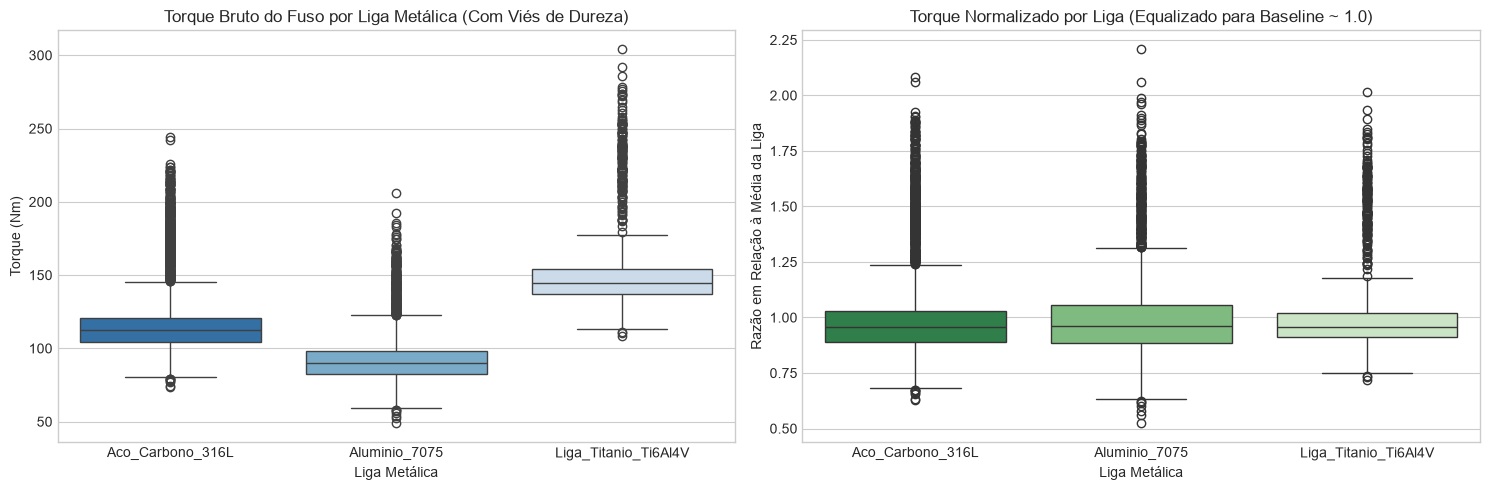

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Comparação Torque Bruto vs. Torque Normalizado por Liga
sns.boxplot(
    data=df_final,
    x='liga_metalica',
    y='torque_fuso_nm',
    palette='Blues_r',
    ax=axes[0]
)
axes[0].set_title('Torque Bruto do Fuso por Liga Metálica (Com Viés de Dureza)')
axes[0].set_xlabel('Liga Metálica')
axes[0].set_ylabel('Torque (Nm)')

sns.boxplot(
    data=df_final,
    x='liga_metalica',
    y='torque_fuso_nm_norm_liga',
    palette='Greens_r',
    ax=axes[1]
)
axes[1].set_title('Torque Normalizado por Liga (Equalizado para Baseline ~ 1.0)')
axes[1].set_xlabel('Liga Metálica')
axes[1].set_ylabel('Razão em Relação à Média da Liga')

plt.tight_layout()
plt.show()


C:\Users\andre_matteussi\AppData\Local\Temp\ipykernel_19696\4201153865.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


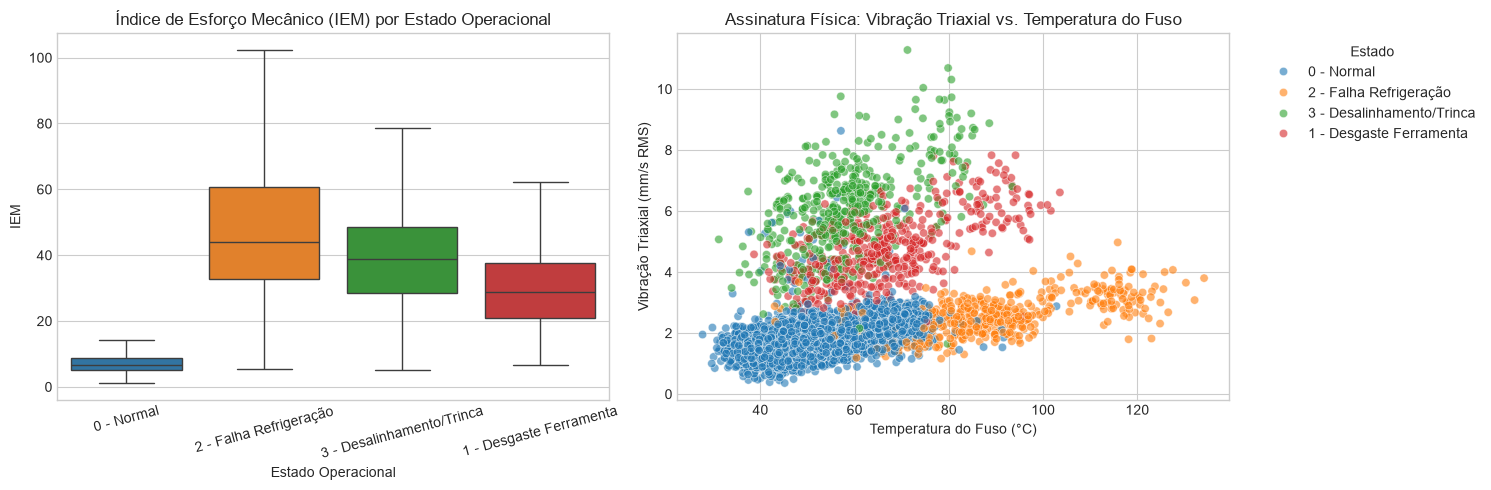

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

mapa_falhas = {
    0: '0 - Normal',
    1: '1 - Desgaste Ferramenta',
    2: '2 - Falha Refrigeração',
    3: '3 - Desalinhamento/Trinca'
}
df_final['diagnostico_rotulo'] = df_final['tipo_falha'].map(mapa_falhas)

# 2. Discriminação do Índice de Esforço Mecânico por Diagnóstico
sns.boxplot(
    data=df_final,
    x='diagnostico_rotulo',
    y='indice_esforco_mecanico',
    palette='tab10',
    showfliers=False,
    ax=axes[0]
)
axes[0].set_title('Índice de Esforço Mecânico (IEM) por Estado Operacional')
axes[0].set_xlabel('Estado Operacional')
axes[0].set_ylabel('IEM')
axes[0].tick_params(axis='x', rotation=15)

# 3. Dispersão: Vibração RMS vs Temperatura do Fuso
sns.scatterplot(
    data=df_final,
    x='temperatura_fuso_c',
    y='vibracao_triaxial_rms_mms',
    hue='diagnostico_rotulo',
    alpha=0.6,
    palette='tab10',
    ax=axes[1]
)
axes[1].set_title('Assinatura Física: Vibração Triaxial vs. Temperatura do Fuso')
axes[1].set_xlabel('Temperatura do Fuso (°C)')
axes[1].set_ylabel('Vibração Triaxial (mm/s RMS)')
axes[1].legend(title='Estado', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()


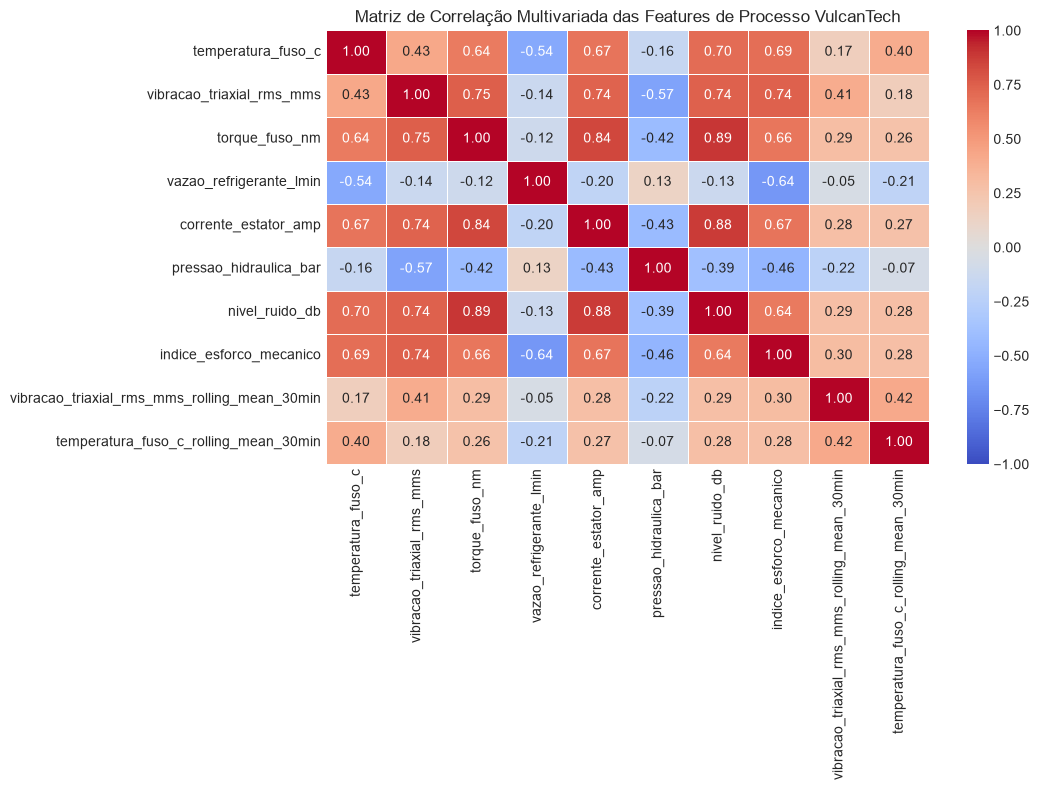

In [7]:
# Matriz de Correlação Linear das Variáveis Principais
colunas_correlacao = [
    'temperatura_fuso_c',
    'vibracao_triaxial_rms_mms',
    'torque_fuso_nm',
    'vazao_refrigerante_lmin',
    'corrente_estator_amp',
    'pressao_hidraulica_bar',
    'nivel_ruido_db',
    'indice_esforco_mecanico',
    'vibracao_triaxial_rms_mms_rolling_mean_30min',
    'temperatura_fuso_c_rolling_mean_30min'
]

plt.figure(figsize=(11, 8))
matriz_corr = df_final[colunas_correlacao].corr()
sns.heatmap(
    matriz_corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1.0,
    vmax=1.0,
    linewidths=0.5
)
plt.title('Matriz de Correlação Multivariada das Features de Processo VulcanTech')
plt.tight_layout()
plt.show()
